In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import os

# Connect to the existing data warehouse
db_path = "../04_Data_Warehouse/breast_cancer_warehouse.db"

if not os.path.exists(db_path):
    raise FileNotFoundError(f"Database not found: {db_path}")

conn = sqlite3.connect(db_path)

# Load warehouse analysis data
query = """
SELECT
    f.Fact_Key,
    f.Patient_Count,
    d.Class,
    t.Tumor_Size,
    t.Inv_Nodes,
    t.Deg_Malig,
    t.Node_Caps,
    c.Irradiat,
    p.Age,
    p.Breast
FROM Fact_Breast_Cancer f
JOIN Dim_Diagnosis d
    ON f.Diagnosis_Key = d.Diagnosis_Key
JOIN Dim_Tumor t
    ON f.Tumor_Key = t.Tumor_Key
JOIN Dim_Clinical c
    ON f.Clinical_Key = c.Clinical_Key
JOIN Dim_Patient p
    ON f.Patient_Key = p.Patient_Key;
"""

analysis_df = pd.read_sql_query(query, conn)

print("Data loaded successfully!")
print("Analysis dataset shape:", analysis_df.shape)
print("\nFirst 5 records:")
display(analysis_df.head())

Data loaded successfully!
Analysis dataset shape: (272, 10)

First 5 records:


,Fact_Key,Patient_Count,Class,Tumor_Size,Inv_Nodes,Deg_Malig,Node_Caps,Irradiat,Age,Breast
0,1,1,0,32.0,1.0,3,0,0,34.5,0
1,2,1,0,22.0,1.0,2,0,0,44.5,1
2,3,1,0,22.0,1.0,2,0,0,44.5,0
3,4,1,0,17.0,1.0,2,0,0,64.5,1
4,5,1,0,2.0,1.0,2,0,0,44.5,1


In [2]:
# Descriptive statistics for the warehouse data

print("Dataset dimensions:", analysis_df.shape)

print("\nNumerical Summary:")
display(
    analysis_df[
        ["Age", "Tumor_Size", "Inv_Nodes", "Deg_Malig"]
    ].describe().round(2)
)

print("\nDiagnosis Class Distribution:")
class_counts = analysis_df["Class"].value_counts().sort_index()

for diagnosis_class, count in class_counts.items():
    percentage = count / len(analysis_df) * 100
    print(
        f"Class {diagnosis_class}: {count} records "
        f"({percentage:.2f}%)"
    )

Dataset dimensions: (272, 10)

Numerical Summary:


,Age,Tumor_Size,Inv_Nodes,Deg_Malig
count,272.00,272.00,272.00,272.00
mean,51.08,26.60,2.63,2.06
std,10.11,10.59,3.51,0.74
min,24.50,2.00,1.00,1.00
25%,44.50,22.00,1.00,2.00
50%,54.50,27.00,1.00,2.00
75%,54.50,32.00,4.00,3.00
max,74.50,52.00,25.00,3.00



Diagnosis Class Distribution:
Class 0: 191 records (70.22%)
Class 1: 81 records (29.78%)


In [3]:
# Compare numerical features by diagnosis class

comparison = (
    analysis_df
    .groupby("Class")
    .agg(
        Total_Records=("Fact_Key", "count"),
        Average_Age=("Age", "mean"),
        Average_Tumor_Size=("Tumor_Size", "mean"),
        Average_Involved_Nodes=("Inv_Nodes", "mean"),
        Average_Degree_of_Malignancy=("Deg_Malig", "mean")
    )
    .round(2)
)

print("Comparison by Diagnosis Class")
display(comparison)

Comparison by Diagnosis Class


,Total_Records,Average_Age,Average_Tumor_Size,Average_Involved_Nodes,Average_Degree_of_Malignancy
Class,,,,,
0,191,51.46,25.56,2.01,1.92
1,81,50.18,29.04,4.11,2.38


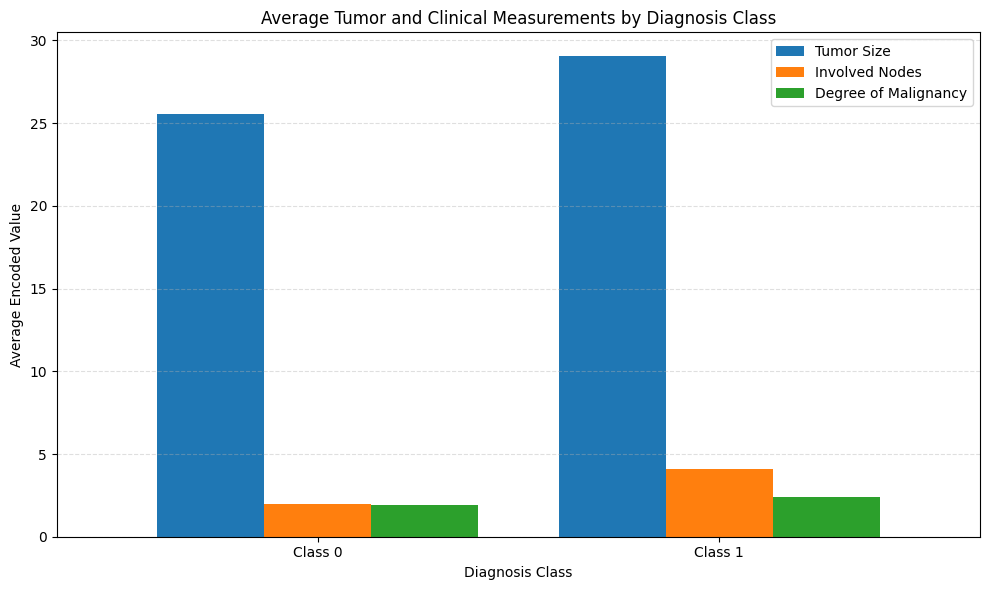

In [4]:
# Compare average clinical and tumor measurements by class

features = [
    "Tumor_Size",
    "Inv_Nodes",
    "Deg_Malig"
]

averages = analysis_df.groupby("Class")[features].mean()

ax = averages.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Average Tumor and Clinical Measurements by Diagnosis Class")
ax.set_xlabel("Diagnosis Class")
ax.set_ylabel("Average Encoded Value")
ax.set_xticklabels(
    ["Class 0", "Class 1"],
    rotation=0
)
ax.legend([
    "Tumor Size",
    "Involved Nodes",
    "Degree of Malignancy"
])
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Diagnosis Class vs Irradiation Status


Class,0,1,All
Irradiat,,,
0,154,51,205
1,37,30,67
All,191,81,272


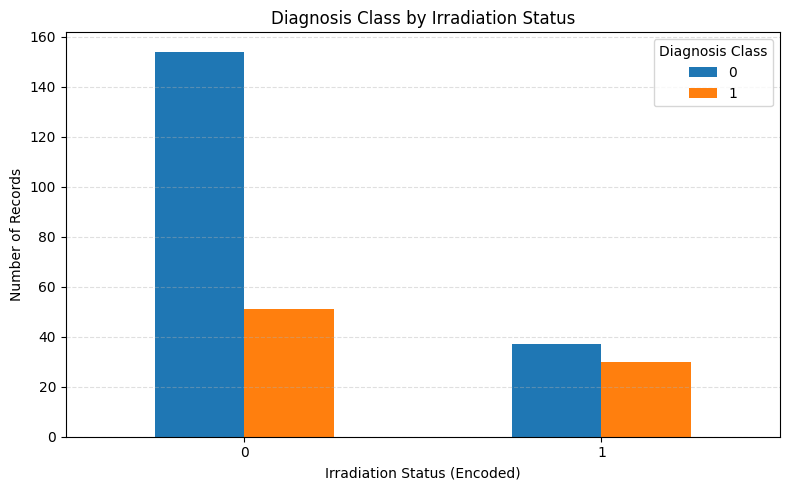

In [5]:
# Analyze diagnosis class by irradiation status

irradiation_analysis = pd.crosstab(
    analysis_df["Irradiat"],
    analysis_df["Class"],
    margins=True
)

print("Diagnosis Class vs Irradiation Status")
display(irradiation_analysis)

# Visualize the relationship
irradiation_plot = pd.crosstab(
    analysis_df["Irradiat"],
    analysis_df["Class"]
)

ax = irradiation_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Diagnosis Class by Irradiation Status")
ax.set_xlabel("Irradiation Status (Encoded)")
ax.set_ylabel("Number of Records")
ax.legend(title="Diagnosis Class")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Tumor Size Summary:
count    272.00
mean      26.60
std       10.59
min        2.00
25%       22.00
50%       27.00
75%       32.00
max       52.00
Name: Tumor_Size, dtype: float64


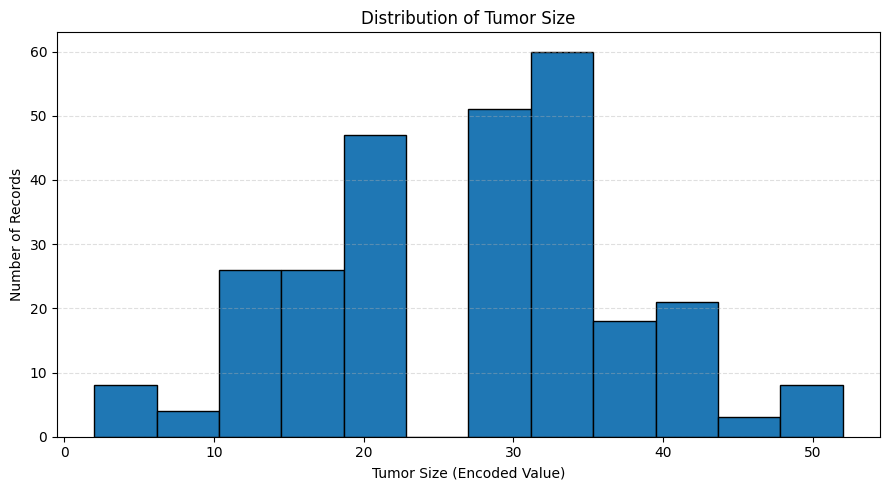

In [6]:
# Analyze the distribution of tumor-size values

print("Tumor Size Summary:")
print(analysis_df["Tumor_Size"].describe().round(2))

plt.figure(figsize=(9, 5))

plt.hist(
    analysis_df["Tumor_Size"],
    bins=12,
    edgecolor="black"
)

plt.title("Distribution of Tumor Size")
plt.xlabel("Tumor Size (Encoded Value)")
plt.ylabel("Number of Records")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Degree of Malignancy Distribution:


,Record_Count
Deg_Malig,
1,66
2,124
3,82


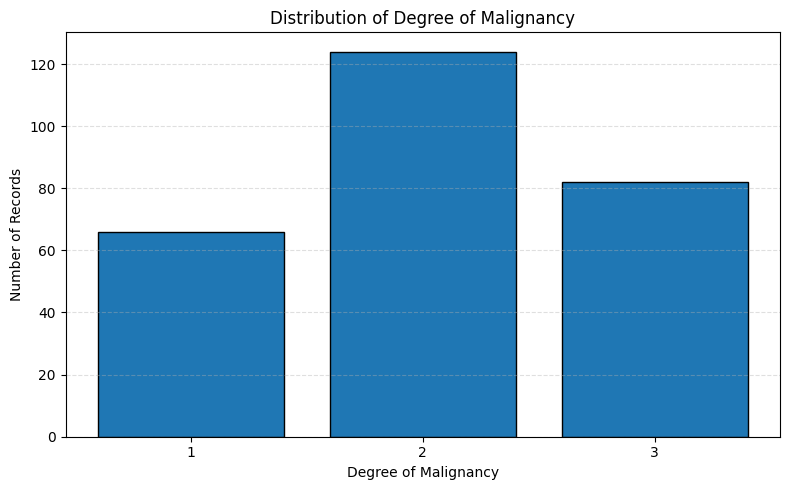

In [7]:
# Count records for each degree of malignancy

malignancy_counts = (
    analysis_df["Deg_Malig"]
    .value_counts()
    .sort_index()
)

print("Degree of Malignancy Distribution:")
display(malignancy_counts.rename("Record_Count").to_frame())

# Plot the distribution
plt.figure(figsize=(8, 5))

plt.bar(
    malignancy_counts.index.astype(str),
    malignancy_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Degree of Malignancy")
plt.xlabel("Degree of Malignancy")
plt.ylabel("Number of Records")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Involved Lymph Nodes Distribution:


,Record_Count
Inv_Nodes,
1.0,200
4.0,36
7.0,16
10.0,10
13.0,3
16.0,6
25.0,1



Involved Nodes by Diagnosis Class:


,count,mean,median,min,max
Class,,,,,
0,191,2.01,1.0,1.0,16.0
1,81,4.11,1.0,1.0,25.0


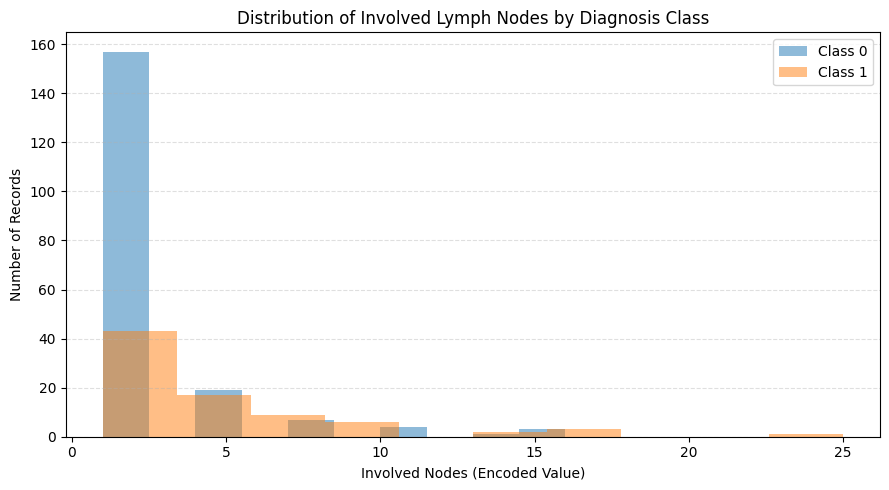

In [8]:
# Distribution of involved lymph nodes

node_counts = (
    analysis_df["Inv_Nodes"]
    .value_counts()
    .sort_index()
)

print("Involved Lymph Nodes Distribution:")
display(node_counts.rename("Record_Count").to_frame())

# Compare involved nodes by diagnosis class
node_comparison = (
    analysis_df.groupby("Class")["Inv_Nodes"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("\nInvolved Nodes by Diagnosis Class:")
display(node_comparison)

# Visualize distribution by class
plt.figure(figsize=(9, 5))

for diagnosis_class in sorted(analysis_df["Class"].unique()):
    values = analysis_df.loc[
        analysis_df["Class"] == diagnosis_class,
        "Inv_Nodes"
    ]
    plt.hist(
        values,
        bins=10,
        alpha=0.5,
        label=f"Class {diagnosis_class}"
    )

plt.title("Distribution of Involved Lymph Nodes by Diagnosis Class")
plt.xlabel("Involved Nodes (Encoded Value)")
plt.ylabel("Number of Records")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [9]:
# Final validation of the analysis dataset

print("FINAL DATA ANALYSIS VALIDATION")
print("-" * 40)

print("Total records:", len(analysis_df))
print("Missing values:", analysis_df.isnull().sum().sum())
print("Duplicate fact keys:", analysis_df["Fact_Key"].duplicated().sum())

print("\nDiagnosis distribution:")
print(analysis_df["Class"].value_counts().sort_index())

print("\nAverage measurements by class:")
display(
    analysis_df.groupby("Class")[
        ["Tumor_Size", "Inv_Nodes", "Deg_Malig"]
    ].mean().round(2)
)

valid = (
    len(analysis_df) == 272
    and analysis_df.isnull().sum().sum() == 0
    and analysis_df["Fact_Key"].duplicated().sum() == 0
    and analysis_df["Class"].value_counts().to_dict() == {0: 191, 1: 81}
)

print("\nDATA ANALYSIS VALIDATION:", "PASSED" if valid else "CHECK REQUIRED")

FINAL DATA ANALYSIS VALIDATION
----------------------------------------
Total records: 272
Missing values: 0
Duplicate fact keys: 0

Diagnosis distribution:
Class
0    191
1     81
Name: count, dtype: int64

Average measurements by class:


,Tumor_Size,Inv_Nodes,Deg_Malig
Class,,,
0,25.56,2.01,1.92
1,29.04,4.11,2.38



DATA ANALYSIS VALIDATION: PASSED
